# Phase 7 - Ensemble optimization (revised)

Question: does a weighted average of the strongest models lower the official cost-weighted loss (or clearly improve reliability) compared with the best single model? If not, the answer is **no ensemble** and the best single model stays.

**What this revision changes compared with the first version** (each change is implemented in the code below):
1. **The weights optimise the official score** (savings and fairness together), not routing cost alone. A fast version of the scorer is used so the search is quick, and it is checked against the real official scorer before it is trusted (section 3b).
2. **The data-starved early folds are removed.** The training part is cut into five time blocks; only blocks 3, 4 and 5 are predicted, by models trained on the blocks before them, so every out-of-fold model has seen at least 40% of the training part.
3. **Three seeds** are used everywhere: weights are tuned once per seed and averaged, and the keep-or-drop rule uses the three-seed spread.
4. **Three time windows** of the out-of-fold rows are tuned separately; a member keeps weight only if it is used in at least two of them. A per-fold table also shows whether the ranking of CatBoost and LightGBM changes over time.
5. **The whole out-of-fold set is calibrated by cross-fitting** (each row is calibrated by a calibrator that never saw it), not by a single half split.

**What this revision cannot do:** fairness is decided by which genuine customers the router flags, so changing blend weights does not control it. If the ensemble loses fairness, that is a router-level problem for Phase 9.

- **Members:** CatBoost (Phase 5 settings), the two LightGBM variants from Phase 6 (plain and robust), the Phase 4 TF-IDF + logistic-regression text model, and TabPFN as an optional extra when it can run on your PC.
- **Blend:** P(y) = sum of w_m P_m(y), weights non-negative and summing to one. Near-ties are broken toward equal weights.
- **Keep-or-drop rule** (unchanged): keep the ensemble only if its saving beats the best single model by more than the seed spread (at least 0.005) **and** the paired-bootstrap interval of the cost gain excludes zero, **and** abusive recall and PR-AUC do not fall, the genuine false-block rate does not rise and fairness does not fall. No ensemble is forced.
- July-September labels are never used.

**How to run:** keep this file in `FULL_CODE/notebooks/`, run Phases 5 and 6 first, and use the project environment. About 10 minutes without TabPFN.

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

for candidate_path in (Path('../src'), Path('src')):
    if candidate_path.exists():
        sys.path.insert(0, str(candidate_path.resolve()))

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from r2sorter.advanced import fit_lgbm, measure
from r2sorter.baselines import build_model, catboost_inputs, predict_full
from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.data import LABELS, load_all
from r2sorter.conformal import cross_fit_calibrated
from r2sorter.ensemble import (blend, evaluate_routing, fairness_masks, fast_official, paired_bootstrap, row_costs,
                               tune_weights_by_official)
from r2sorter.nlp import classification_report
from r2sorter.protocol import TEXT_COLUMNS, build_protocol
from r2sorter.router import route
from r2sorter import tabpfn_runner
from sklearn.metrics import average_precision_score

pd.set_option('display.width', 220, 'display.max_columns', 50, 'display.max_colwidth', 70)
SEEDS = (0, 1, 2)
CAL_METHOD = 'isotonic'   # same calibrator as Phases 5-7 so the numbers stay comparable
AB = LABELS.index('abusive')
cfg = load_config()
data = load_all(cfg)
REPORTS = Path('../reports') if Path('../reports').exists() else Path('reports')
MODELS = REPORTS.parent / 'models' / 'phase7'
FIG = REPORTS / 'figures'
for folder in (REPORTS, MODELS, FIG):
    folder.mkdir(parents=True, exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'lightgbm': lgb.__version__}
try:
    import catboost
    versions['catboost'] = catboost.__version__
except ImportError:
    raise SystemExit('catboost is required: pip install catboost') from None
print(versions)

{'python': '3.13.17', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}


## 1. Data and the settled Phase 5 reference
Same protocol as Phases 5 and 6: chronological 70/10/20 split, preprocessing fitted on train only, rolling-origin text scores for train rows. The saved Phase 5 predictions must sit on exactly the same validation rows.

In [2]:
protocol = build_protocol(cfg, data)
parts, y_idx, y_abuse = protocol.parts, protocol.y_index, protocol.y_abuse
x_train, x_cal, x_test = (protocol.matrix('tree', p) for p in ('train', 'calibration', 'test'))
saved = pd.read_csv(REPORTS / 'phase5_selected_validation_predictions.csv')
assert saved['return_id'].tolist() == parts['test']['return_id'].tolist(), 'Phase 5 rows differ from this protocol'
phase5 = pd.read_csv(REPORTS / 'phase5_model_comparison.csv').set_index(['model', 'arm']).loc[('catboost', 'C + all text-derived')]
print('rows: train', len(x_train), '| calibration', len(x_cal), '| validation (May-June)', len(x_test), '| features', x_train.shape[1])
print('Phase 5 CatBoost reference: calibrated saving', round(float(phase5['cal_saving']), 4), '+/-', round(float(phase5['saving_sd']), 4))

rows: train 30183 | calibration 4388 | validation (May-June) 8497 | features 90
Phase 5 CatBoost reference: calibrated saving 0.3019 +/- 0.0098


## 2. Candidate members: fit once on the full training part
CatBoost uses the Phase 5 settings; LightGBM plain and robust use the Phase 6 fixed settings. The text member is the Phase 4 text-only classifier, whose four-class probabilities are already columns of the feature matrix (rolling-origin out-of-fold on train, fitted-on-train on the later parts). Three seeds for each stochastic member give a seed spread for the keep-or-drop rule.

In [3]:
cb_train, cat_names = catboost_inputs(x_train)
cb_cal, cb_test = catboost_inputs(x_cal)[0], catboost_inputs(x_test)[0]

def text_probs(frame):
    block = frame[TEXT_COLUMNS].to_numpy(dtype=float)
    return block / block.sum(axis=1, keepdims=True)

def fit_member(name, seed, fit_x, fit_y, cb_fit_x):
    if name == 'catboost':
        model = build_model('catboost', seed, cat_names)
        model.fit(cb_fit_x, fit_y)
        return model
    return fit_lgbm(name.replace('lightgbm_', ''), seed, fit_x, fit_y)

def member_predict(name, model, cb_frame, frame):
    return predict_full(model, cb_frame if name == 'catboost' else frame)

STOCHASTIC = ('catboost', 'lightgbm_plain', 'lightgbm_robust')
member = {}          # (name, seed) -> {'cal': probs, 'test': probs, 'eff': {...}}
fitted = {}          # (name, seed) -> fitted model (kept for the saved bundle)
for name in STOCHASTIC:
    for seed in SEEDS:
        (model, (pc, pt)), eff = measure(
            lambda n=name, s=seed: fit_member(n, s, x_train, y_idx['train'], cb_train),
            lambda m, n=name: (m, (member_predict(n, m, cb_cal, x_cal), member_predict(n, m, cb_test, x_test))),
            len(x_cal) + len(x_test))
        member[(name, seed)] = {'cal': pc, 'test': pt, 'eff': eff}
        fitted[(name, seed)] = model
    print('fitted', name)
text_member = {'cal': text_probs(x_cal), 'test': text_probs(x_test),
               'eff': {'train_seconds': 0.0, 'inference_ms_per_1k_rows': 0.0, 'rss_growth_mb': 0.0}}
for seed in SEEDS:
    member[('text_logreg', seed)] = text_member

fitted catboost


fitted lightgbm_plain


fitted lightgbm_robust


## 3. Does the retrained CatBoost match Phase 5?
The ensemble builds on these predictions, so they must be settled first: the retrained CatBoost should reproduce the Phase 5 calibrated saving within the seed spread.

In [4]:
AB_CAL = y_abuse['calibration']
results, store = [], {}

def evaluate_model(label, seed, probs_cal, probs_test, eff=None):
    calibrator = AbuseCalibrator('isotonic').fit(probs_cal[:, AB], AB_CAL)
    p_cal = calibrator.transform(probs_test[:, AB])
    row = evaluate_routing(label, probs_test, p_cal, parts['test'], y_abuse['test'], cfg)
    row.update({'seed': seed, **(eff or {})})
    results.append(row)
    store[(label, seed)] = {'probs': probs_test, 'p_cal': p_cal, 'calibrator': calibrator}

def efficiency(names, seed):
    effs = [member[(n, seed)]['eff'] for n in names]
    return {'train_seconds': sum(e['train_seconds'] for e in effs), 'inference_ms_per_1k_rows': sum(e['inference_ms_per_1k_rows'] for e in effs),
            'rss_growth_mb': max(e['rss_growth_mb'] for e in effs)}

for name in STOCHASTIC:
    for seed in SEEDS:
        m = member[(name, seed)]
        evaluate_model(name, seed, m['cal'], m['test'], m['eff'])
evaluate_model('text_logreg', 0, text_member['cal'], text_member['test'], text_member['eff'])

cat_rows = pd.DataFrame(results).query("model == 'catboost'")
gap = cat_rows['saving_vs_approve_all'].mean() - float(phase5['cal_saving'])
print(f"retrained CatBoost saving {cat_rows['saving_vs_approve_all'].mean():.4f} vs Phase 5 {float(phase5['cal_saving']):.4f} (gap {gap:+.4f}, Phase 5 seed spread {float(phase5['saving_sd']):.4f})")
print('official score', cat_rows['official_score'].mean().round(4), '| genuine escalated', cat_rows['genuine_escalated'].mean())
print('MATCHES PHASE 5' if abs(gap) <= max(2 * float(phase5['saving_sd']), 0.01) else 'DIFFERS from Phase 5: check versions before trusting the ensemble')

retrained CatBoost saving 0.3052 vs Phase 5 0.3019 (gap +0.0033, Phase 5 seed spread 0.0098)
official score 0.3536 | genuine escalated 1.0
MATCHES PHASE 5


## 3b. Is the fast official score the real official score?
The weight search needs thousands of score evaluations, so it uses a fast re-implementation of the scorer (savings, and fairness earned in proportion to savings). Before it is trusted, it must reproduce the real `evaluate.py` result on the validation rows.

In [5]:
masks_test = fairness_masks(parts['test'], cfg)
real = next(r for r in results if r['model'] == 'catboost' and r['seed'] == 0)
fast = fast_official(store[('catboost', 0)]['p_cal'], y_abuse['test'], masks_test, cfg)
print(f"official scorer: score {real['official_score']:.6f}, fairness {real['fairness_score']:.6f}, saving {real['saving_vs_approve_all']:.6f}")
print(f"fast version   : score {fast['primary']:.6f}, fairness {fast['fairness']:.6f}, saving {fast['savings']:.6f}")
proxy_ok = abs(real['official_score'] - fast['primary']) < 1e-4 and abs(real['fairness_score'] - fast['fairness']) < 1e-4
assert proxy_ok, 'the fast score differs from the official scorer: do not trust the weight search'
print('FAST SCORE MATCHES THE OFFICIAL SCORER')

official scorer: score 0.363110, fairness 0.734503, saving 0.308870
fast version   : score 0.363110, fairness 0.734503, saving 0.308870
FAST SCORE MATCHES THE OFFICIAL SCORER


## 4. Learning the weights without peeking: time-ordered out-of-fold predictions
The training part is cut into five consecutive time blocks. Blocks 3, 4 and 5 are predicted by models trained **only on the earlier blocks** (an expanding window, so the smallest training set is 40% of the training part). This is repeated for three seeds. The text member's training-row probabilities are already out-of-fold. The validation window is not involved in any of these steps.

In [6]:
N_BLOCKS, FIRST_OOF_BLOCK = 5, 2          # blocks are numbered from 0; block 2 is the first one predicted (trained on blocks 0-1 = 40%)
blocks = np.array_split(np.arange(len(x_train)), N_BLOCKS)
oof_blocks = blocks[FIRST_OOF_BLOCK:]
oof_rows = np.concatenate(oof_blocks)
fold_of_row = np.concatenate([np.full(len(b), n) for n, b in enumerate(oof_blocks)])
oof_by_seed = {}
started = time.perf_counter()
for seed in SEEDS:
    oof_seed = {name: np.zeros((len(oof_rows), len(LABELS))) for name in (*STOCHASTIC, 'text_logreg')}
    position = 0
    for k in range(FIRST_OOF_BLOCK, N_BLOCKS):
        fit_rows, pred_rows = np.concatenate(blocks[:k]), blocks[k]
        for name in STOCHASTIC:
            model = fit_member(name, seed, x_train.iloc[fit_rows], y_idx['train'][fit_rows], cb_train.iloc[fit_rows])
            oof_seed[name][position:position + len(pred_rows)] = member_predict(name, model, cb_train.iloc[pred_rows], x_train.iloc[pred_rows])
        oof_seed['text_logreg'][position:position + len(pred_rows)] = text_probs(x_train.iloc[pred_rows])
        position += len(pred_rows)
    oof_by_seed[seed] = oof_seed
    print('seed', seed, 'done')
oof_y, oof_abuse = y_idx['train'][oof_rows], y_abuse['train'][oof_rows]
oof_masks = fairness_masks(parts['train'].iloc[oof_rows], cfg)
names = list(oof_by_seed[SEEDS[0]])
print('out-of-fold rows:', len(oof_rows), '| abusive:', int(oof_abuse.sum()), '| smallest training set:', len(np.concatenate(blocks[:FIRST_OOF_BLOCK])), 'rows',
      '| minutes:', round((time.perf_counter() - started) / 60, 1))

seed 0 done


seed 1 done


seed 2 done
out-of-fold rows: 18109 | abusive: 1561 | smallest training set: 12074 rows | minutes: 4.1


In [7]:
# Does the ranking of the models change over time? Official score (fast version) per out-of-fold block, seed 0, cross-fit calibrated.
fold_rows = []
for model_name in ('catboost', 'lightgbm_plain', 'lightgbm_robust'):
    p_oof = cross_fit_calibrated(oof_by_seed[SEEDS[0]][model_name][:, AB], oof_abuse, CAL_METHOD, folds=5)
    for fold in range(N_BLOCKS - FIRST_OOF_BLOCK):
        rows = fold_of_row == fold
        result = fast_official(p_oof[rows], oof_abuse[rows], {key: value[rows] for key, value in oof_masks.items()}, cfg)
        fold_rows.append({'model': model_name, 'block': fold + FIRST_OOF_BLOCK + 1, 'official_score': result['primary'], 'fairness': result['fairness'], 'saving': result['savings']})
pd.DataFrame(fold_rows).pivot(index='model', columns='block', values=['official_score', 'fairness', 'saving']).round(3)

official_score               fairness               saving              
block                        3      4      5        3      4      5      3      4      5
model                                                                                   
catboost                 0.303  0.320  0.379    0.735  0.887  0.896  0.223  0.203  0.285
lightgbm_plain           0.362  0.319  0.370    0.890  0.811  0.803  0.264  0.225  0.299
lightgbm_robust          0.316  0.279  0.343    0.731  0.681  0.842  0.242  0.203  0.250

### Tuning the weights (official score, three seeds, three windows)
For each seed the weights maximise the fast official score of the cross-fit-calibrated blend over all out-of-fold rows (grid step 0.1); scores within 0.002 of the best are treated as tied and the weights closest to equal win. The three seeds' weight vectors are averaged. Then the out-of-fold rows are split into three consecutive windows and tuned again (seed 0): a member must receive weight in at least two windows to keep its weight.

In [8]:
def tune(row_slice, seed):
    members = [oof_by_seed[seed][n][row_slice] for n in names]
    sub_masks = {key: value[row_slice] for key, value in oof_masks.items()}
    return tune_weights_by_official(members, oof_abuse[row_slice], sub_masks, cfg, method=CAL_METHOD, step=0.1)

everything = slice(None)
per_seed_weights = {seed: tune(everything, seed)[0] for seed in SEEDS}
weights_mean = np.mean(list(per_seed_weights.values()), axis=0)
weights_mean /= weights_mean.sum()
thirds = np.array_split(np.arange(len(oof_rows)), 3)
window_weights = {f'window {i + 1}': tune(window, SEEDS[0])[0] for i, window in enumerate(thirds)}
stability = pd.DataFrame({**{f'seed {s}': w for s, w in per_seed_weights.items()}, 'mean of seeds': weights_mean, **window_weights}, index=names).round(2)
used_in_windows = (pd.DataFrame(window_weights, index=names) > 0).sum(axis=1)
keep_member = (used_in_windows >= 2).to_numpy()
weights_oof = weights_mean * keep_member
weights_oof = weights_oof / weights_oof.sum() if weights_oof.sum() > 0 else np.eye(len(names))[0]
stability['final'] = weights_oof.round(2)
print('members dropped for being used in fewer than 2 of 3 windows:', [n for n, keep in zip(names, keep_member) if not keep] or 'none')
stability

members dropped for being used in fewer than 2 of 3 windows: none


,seed 0,seed 1,seed 2,mean of seeds,window 1,window 2,window 3,final
catboost,0.2,0.3,0.5,0.33,0.1,0.5,0.7,0.33
lightgbm_plain,0.6,0.4,0.4,0.47,0.5,0.4,0.1,0.47
lightgbm_robust,0.1,0.1,0.0,0.07,0.1,0.1,0.1,0.07
text_logreg,0.1,0.2,0.1,0.13,0.3,0.0,0.1,0.13


In [9]:
equal = np.full(len(names), 1 / len(names))
oof_members = [oof_by_seed[SEEDS[0]][n] for n in names]
candidates_oof = {'tuned weights': weights_oof, 'equal weights': equal, 'CatBoost only': np.eye(len(names))[names.index('catboost')],
                  'LightGBM plain only': np.eye(len(names))[names.index('lightgbm_plain')]}
reference = pd.DataFrame({label: fast_official(cross_fit_calibrated(blend(oof_members, w)[:, AB], oof_abuse, CAL_METHOD, folds=5), oof_abuse, oof_masks, cfg)
                          for label, w in candidates_oof.items()}).T[['primary', 'savings', 'fairness', 'genuine_escalated']].round(4)
print('learned weights:', dict(zip(names, weights_oof.round(2).tolist())))
reference.rename(columns={'primary': 'official_score (out-of-fold)'})

learned weights: {'catboost': 0.33, 'lightgbm_plain': 0.47, 'lightgbm_robust': 0.07, 'text_logreg': 0.13}


,official_score (out-of-fold),savings,fairness,genuine_escalated
tuned weights,0.3651,0.2746,0.8642,3.0
equal weights,0.3632,0.2687,0.8754,2.0
CatBoost only,0.3399,0.2391,0.8628,2.0
LightGBM plain only,0.3602,0.2657,0.8712,4.0


## 5. Ensembles evaluated once on the validation window
For every seed: blend the members' calibration-part and validation probabilities with (a) equal weights and (b) the out-of-fold-tuned weights, refit the isotonic calibrator on the **calibration part** for the blended P(abusive) (blending shifts probabilities), and route under the official cost matrix.

In [10]:
for seed in SEEDS:
    cal_list = [member[(n, seed)]['cal'] for n in names]
    test_list = [member[(n, seed)]['test'] for n in names]
    eff = efficiency(names, seed)
    evaluate_model('ensemble: equal weights', seed, blend(cal_list, equal), blend(test_list, equal), eff)
    evaluate_model('ensemble: tuned weights', seed, blend(cal_list, weights_oof), blend(test_list, weights_oof), eff)
print('done')

done


## 6. TabPFN as an extra member (optional, runs only on a machine where it is installed)
TabPFN needs `pip install tabpfn`, PyTorch and downloaded weights; it uses a stratified sub-sample of the training part and is slow on a CPU. Producing out-of-fold TabPFN predictions inside the training period would be far too slow, so this variant is deliberately kept **separate**: the weights of the five-member blend are tuned on the **calibration part** (a smaller, less reliable tuning set, and the calibrator is then fitted on that same part, which makes this variant slightly optimistic). It is reported as an extra row and never replaces the main decision rule. The key is read from the git-ignored `tabpfn_key.py`. Predictions are cached, so a re-run is fast. Set `RUN_TABPFN = False` to skip.

In [11]:
RUN_TABPFN = True
TABPFN_MAX_TRAIN_ROWS = 10_000
TABPFN_TIME_BUDGET_MIN = 25
cache = REPORTS / 'phase7_tabpfn_probabilities.npz'
tabpfn_status = {'package_installed': tabpfn_runner.package_installed(), 'train_rows_used_if_run': min(len(x_train), TABPFN_MAX_TRAIN_ROWS)}
tab = None
if RUN_TABPFN and cache.exists():
    stored = np.load(cache)
    if len(stored['cal']) == len(x_cal) and len(stored['test']) == len(x_test):
        tab, tabpfn_status['outcome'] = (stored['cal'], stored['test']), 'loaded cached TabPFN predictions'
if tab is None and RUN_TABPFN and tabpfn_status['package_installed']:
    try:
        tabpfn_status['key'] = tabpfn_runner.load_key()
        (tab_cal, tab_test), info = tabpfn_runner.fit_predict(x_train, y_idx['train'], [x_cal, x_test], max_train_rows=TABPFN_MAX_TRAIN_ROWS,
                                                             time_budget_min=TABPFN_TIME_BUDGET_MIN)
        np.savez(cache, cal=tab_cal, test=tab_test)
        tab, tabpfn_status['outcome'] = (tab_cal, tab_test), 'ran'
        tabpfn_status.update(info)
    except Exception as error:   # no weights / network / memory / over the time budget
        tabpfn_status['outcome'] = f'not completed: {type(error).__name__}: {error}'
elif tab is None:
    tabpfn_status['outcome'] = 'not run: ' + ('disabled by RUN_TABPFN' if not RUN_TABPFN else 'package tabpfn is not installed in this environment')
if tab is not None:
    tab_eff = {'train_seconds': tabpfn_status.get('train_seconds', np.nan), 'inference_ms_per_1k_rows': tabpfn_status.get('inference_ms_per_1k_rows', np.nan), 'rss_growth_mb': np.nan}
    evaluate_model('tabpfn', 0, tab[0], tab[1], tab_eff)
    five = [member[(n, 0)]['cal'] for n in names] + [tab[0]]
    five_test = [member[(n, 0)]['test'] for n in names] + [tab[1]]
    w5, _ = tune_weights_by_official(five, AB_CAL, fairness_masks(parts['calibration'], cfg), cfg, method=CAL_METHOD, step=0.1)
    tabpfn_status['five_member_weights'] = dict(zip([*names, 'tabpfn'], w5.round(2).tolist()))
    evaluate_model('ensemble + TabPFN (weights on calibration part)', 0, blend(five, w5), blend(five_test, w5), efficiency(names, 0))
print(json.dumps(tabpfn_status, indent=2, default=str))

{
  "package_installed": false,
  "train_rows_used_if_run": 10000,
  "outcome": "not run: package tabpfn is not installed in this environment"
}


## 7. One compact comparison
Means over seeds (text-only and TabPFN are single runs). Cost per request is the mean official cost after calibrated routing, lower is better. The last columns are efficiency: seconds to train, milliseconds to score 1,000 requests, and approximate memory growth.

In [12]:
frame = pd.DataFrame(results)
order = list(dict.fromkeys(frame['model']))
comparison = frame.groupby('model', sort=False).agg(
    official_score=('official_score', 'mean'), cost_per_request=('cost_per_request', 'mean'), saving=('saving_vs_approve_all', 'mean'),
    saving_sd=('saving_vs_approve_all', 'std'), abusive_PR_AUC=('abusive_PR_AUC', 'mean'), abusive_recall=('abusive_recall', 'mean'),
    abusive_caught=('abusive_caught_by_routing', 'mean'), false_block_rate=('genuine_false_block_rate', 'mean'),
    genuine_escalated=('genuine_escalated', 'mean'), fairness=('fairness_score', 'mean'), brier=('brier_calibrated', 'mean'),
    ece=('ece_calibrated', 'mean'), train_s=('train_seconds', 'mean'), infer_ms_per_1k=('inference_ms_per_1k_rows', 'mean')).reindex(order).round(4)
comparison['saving_sd'] = comparison['saving_sd'].fillna(0.0)
comparison.to_csv(REPORTS / 'phase7_model_comparison.csv')
comparison

,official_score,cost_per_request,saving,saving_sd,abusive_PR_AUC,abusive_recall,abusive_caught,false_block_rate,genuine_escalated,fairness,brier,ece,train_s,infer_ms_per_1k
model,,,,,,,,,,,,,,
catboost,0.3536,0.0572,0.3052,0.0089,0.7040,0.4683,0.5742,0.0178,1.0000,0.6998,0.0412,0.0136,36.5967,3.5133
lightgbm_plain,0.3066,0.0605,0.2644,0.0350,0.7212,0.5722,0.5866,0.0153,6.0000,0.6076,0.0386,0.0130,3.0133,25.9100
lightgbm_robust,0.2950,0.0616,0.2515,0.0214,0.6869,0.6085,0.5188,0.0133,4.3333,0.5944,0.0418,0.0148,2.2100,25.4433
text_logreg,-0.0072,0.0831,-0.0103,0.0000,0.1674,0.0601,0.0272,0.0053,0.0000,0.8517,0.0732,0.0186,0.0000,0.0000
ensemble: equal weights,0.3112,0.0577,0.2980,0.0040,0.7137,0.4597,0.5899,0.0160,4.0000,0.5128,0.0397,0.0135,41.8200,54.8667
ensemble: tuned weights,0.3330,0.0556,0.3245,0.0037,0.7264,0.5041,0.5751,0.0130,2.0000,0.5296,0.0383,0.0129,41.8200,54.8667


## 8. Keep or drop the ensemble
The ensemble candidate is fixed in advance: **ensemble: tuned weights**. The reference is the best single model by mean calibrated saving (text-only and TabPFN-variant rows are excluded from the reference unless TabPFN ran alone). The cost gain is bootstrapped over validation requests (seed 0, 2,000 resamples, paired).

In [13]:
singles = [m for m in ('catboost', 'lightgbm_plain', 'lightgbm_robust', 'tabpfn') if m in comparison.index]
best_single = comparison.loc[singles, 'saving'].idxmax()
candidate = 'ensemble: tuned weights'
b, c = comparison.loc[best_single], comparison.loc[candidate]
cost_gain, low, high = paired_bootstrap(row_costs(store[(best_single, 0)]['p_cal'], y_abuse['test'], cfg) - row_costs(store[(candidate, 0)]['p_cal'], y_abuse['test'], cfg))
needed = max(b['saving_sd'], c['saving_sd'], 0.005)
checks = {
    f"saving gain {c['saving'] - b['saving']:+.4f} exceeds the seed spread {needed:.4f}": c['saving'] - b['saving'] > needed,
    f'paired-bootstrap 95% interval of cost gain per request [{low:+.4f}, {high:+.4f}] excludes zero': low > 0,
    f"abusive recall {c['abusive_recall']:.3f} vs {b['abusive_recall']:.3f} does not fall": c['abusive_recall'] >= b['abusive_recall'],
    f"abusive PR-AUC {c['abusive_PR_AUC']:.3f} vs {b['abusive_PR_AUC']:.3f} does not fall": c['abusive_PR_AUC'] >= b['abusive_PR_AUC'],
    f"genuine false-block rate {c['false_block_rate']:.4f} vs {b['false_block_rate']:.4f} does not rise": c['false_block_rate'] <= b['false_block_rate'],
    f"fairness {c['fairness']:.3f} vs {b['fairness']:.3f} does not fall (tolerance 0.01)": c['fairness'] >= b['fairness'] - 0.01,
}
for text, passed in checks.items():
    print('PASS' if passed else 'FAIL', '|', text)
keep_ensemble = all(checks.values())
final_name = candidate if keep_ensemble else best_single
print(f'\nreference (best single model): {best_single}; official score {b["official_score"]:.3f}; candidate ensemble {c["official_score"]:.3f}')
print('VERDICT:', 'KEEP the ensemble' if keep_ensemble else f'NO ensemble: keep {best_single} as the final model')
print(f'efficiency: ensemble trains in {c["train_s"]:.0f}s and scores 1,000 requests in {c["infer_ms_per_1k"]:.0f} ms; {best_single}: {b["train_s"]:.0f}s and {b["infer_ms_per_1k"]:.0f} ms')

PASS | saving gain +0.0193 exceeds the seed spread 0.0089
FAIL | paired-bootstrap 95% interval of cost gain per request [-0.0016, +0.0039] excludes zero
PASS | abusive recall 0.504 vs 0.468 does not fall
PASS | abusive PR-AUC 0.726 vs 0.704 does not fall
PASS | genuine false-block rate 0.0130 vs 0.0178 does not rise
FAIL | fairness 0.530 vs 0.700 does not fall (tolerance 0.01)

reference (best single model): catboost; official score 0.354; candidate ensemble 0.333
VERDICT: NO ensemble: keep catboost as the final model
efficiency: ensemble trains in 42s and scores 1,000 requests in 55 ms; catboost: 37s and 4 ms


## 9. Cost and abusive PR-AUC across models
Two panels because the two measures have different scales. Orange = reference single model, aqua = ensembles, blue = other single models.

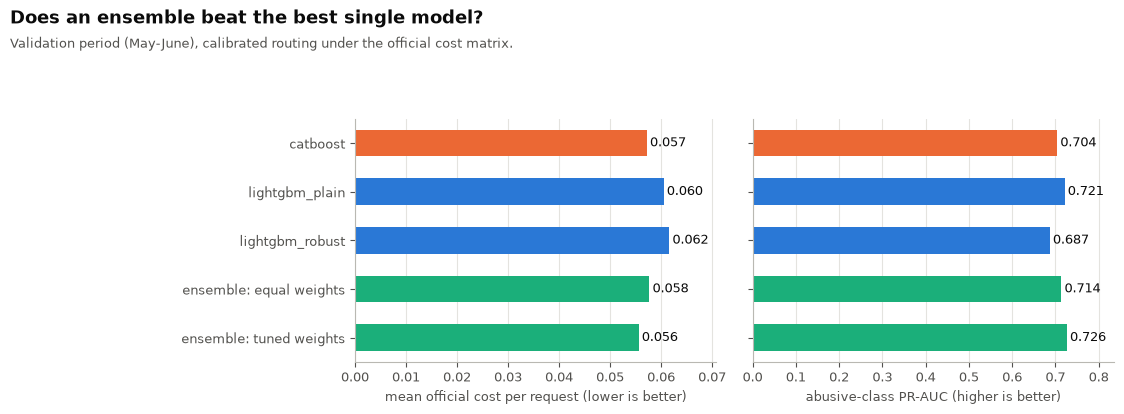

In [14]:
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'

def style(ax, grid_axis='x'):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

shown = [m for m in comparison.index if m != 'text_logreg']
colours = [AQUA if m.startswith('ensemble') else ORANGE if m == best_single else BLUE for m in shown]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
fig.subplots_adjust(top=0.72, left=0.31, right=0.97, bottom=0.14, wspace=0.1)
for ax, column, label in ((axes[0], 'cost_per_request', 'mean official cost per request (lower is better)'), (axes[1], 'abusive_PR_AUC', 'abusive-class PR-AUC (higher is better)')):
    values = comparison.loc[shown, column].to_numpy()
    bars = ax.barh(shown[::-1], values[::-1], color=colours[::-1], height=0.55)
    for bar, value in zip(bars, values[::-1]):
        ax.text(bar.get_width() + values.max() * 0.01, bar.get_y() + bar.get_height() / 2, f'{value:.3f}', va='center', fontsize=9, color=INK)
    ax.set_xlim(0, values.max() * 1.15)
    ax.set_xlabel(label, color=MUTED, fontsize=9)
    style(ax)
fig.text(0.01, 0.98, 'Does an ensemble beat the best single model?', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.915, 'Validation period (May-June), calibrated routing under the official cost matrix.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase7_cost_and_pr_auc.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Final weights
Weights learned on time-ordered out-of-fold predictions inside the training period (section 4). A member with weight zero adds nothing under the official cost.

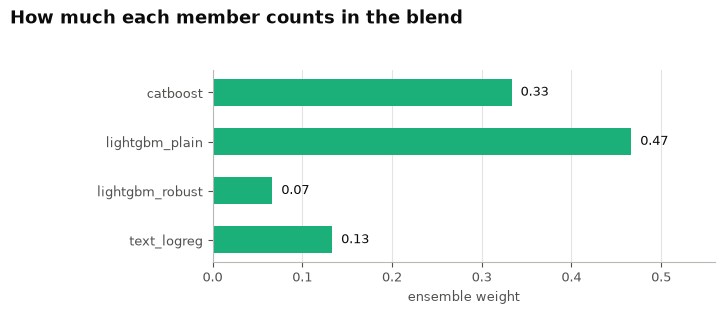

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
fig.subplots_adjust(top=0.78, left=0.28, right=0.95, bottom=0.18)
bars = ax.barh(names[::-1], weights_oof[::-1], color=AQUA, height=0.55)
for bar, value in zip(bars, weights_oof[::-1]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'{value:.2f}', va='center', fontsize=9, color=INK)
ax.set_xlim(0, max(weights_oof.max() * 1.2, 0.2))
ax.set_xlabel('ensemble weight', color=MUTED, fontsize=9)
style(ax)
fig.text(0.01, 0.97, 'How much each member counts in the blend', fontsize=13, fontweight='bold', color=INK, va='top')
fig.savefig(FIG / 'phase7_weights.png', dpi=150, bbox_inches='tight')
plt.show()
pd.DataFrame({'weight': weights_oof}, index=names).round(3).to_csv(REPORTS / 'phase7_weights.csv')

## 11. Confusion matrix of the final model

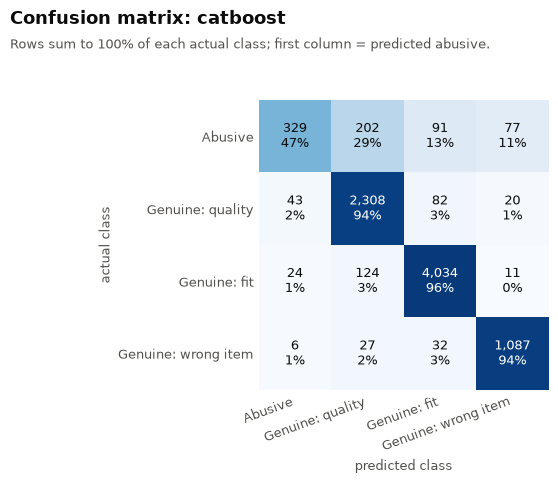

,actual,predicted,count
0,Abusive,Genuine: quality,202
1,Genuine: fit,Genuine: quality,124
2,Abusive,Genuine: fit,91
3,Genuine: quality,Genuine: fit,82
4,Abusive,Genuine: wrong item,77


In [16]:
report = classification_report(store[(final_name, 0)]['probs'], parts['test']['label'])
cm = report['confusion']
labels_short = {'abusive': 'Abusive', 'genuine_quality_issue': 'Genuine: quality', 'genuine_fit_issue': 'Genuine: fit', 'genuine_wrong_item': 'Genuine: wrong item'}
row_share = cm.div(cm.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(6.4, 5.0))
fig.subplots_adjust(top=0.8, left=0.3, right=0.95, bottom=0.22)
ax.imshow(row_share.to_numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels([labels_short[l] for l in LABELS], rotation=20, ha='right', fontsize=9)
ax.set_yticks(range(4))
ax.set_yticklabels([labels_short[l] for l in LABELS], fontsize=9)
ax.set_xlabel('predicted class', color=MUTED, fontsize=9)
ax.set_ylabel('actual class', color=MUTED, fontsize=9)
for i in range(4):
    for j in range(4):
        value = row_share.iat[i, j]
        ax.text(j, i, f'{cm.iat[i, j]:,}\n{value:.0%}', ha='center', va='center', fontsize=9, color='white' if value > 0.55 else INK)
for side in ax.spines.values():
    side.set_visible(False)
ax.tick_params(colors=MUTED, length=0)
fig.text(0.01, 0.98, f'Confusion matrix: {final_name}', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.925, 'Rows sum to 100% of each actual class; first column = predicted abusive.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase7_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
pairs = [(labels_short[a], labels_short[b], int(cm.loc[f'true_{a}', f'pred_{b}'])) for a in LABELS for b in LABELS if a != b]
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:5], columns=['actual', 'predicted', 'count'])

## 12. May versus June stability
Same predictions, evaluated separately by month. A real gain should show up in both months.

In [17]:
month = parts['test']['return_request_date'].dt.to_period('M').astype(str).to_numpy()
rows = []
for model_name in dict.fromkeys([best_single, candidate]):
    for m in sorted(set(month)):
        mask = month == m
        y_m = y_abuse['test'][mask]
        costs = row_costs(store[(model_name, 0)]['p_cal'][mask], y_m, cfg)
        approve_all = np.where(y_m == 1, cfg['costs']['abusive']['auto_approve'], cfg['costs']['genuine']['auto_approve'])
        rows.append({'model': model_name, 'month': m, 'rows': int(mask.sum()), 'saving_vs_approve_all': 1 - costs.sum() / approve_all.sum(),
                     'abusive_PR_AUC': average_precision_score(y_m, store[(model_name, 0)]['probs'][mask, AB])})
stability = pd.DataFrame(rows).pivot(index='model', columns='month', values=['saving_vs_approve_all', 'abusive_PR_AUC']).round(3)
stability.to_csv(REPORTS / 'phase7_temporal_stability.csv')
stability

saving_vs_approve_all         abusive_PR_AUC        
month                                 2026-05 2026-06        2026-05 2026-06
model                                                                       
catboost                                0.318   0.301          0.728   0.695
ensemble: tuned weights                 0.317   0.334          0.753   0.705

## 13. Save the final model, predictions and configuration
The bundle in `models/phase7/` holds every tabular member (seed 0), the isotonic calibrator, and `ensemble_config.json` with the member list, weights, tuning protocol and the text-component description. The text member is the Phase 4 TF-IDF + logistic-regression scores that `build_protocol` rebuilds, and its validation outputs are stored with the predictions below. If the ensemble was not kept, the config records the single best model as final.

In [18]:
fitted[('catboost', 0)].save_model(str(MODELS / 'catboost_seed0.cbm'))
for variant in ('lightgbm_plain', 'lightgbm_robust'):
    fitted[(variant, 0)].booster_.save_model(str(MODELS / f'{variant}_seed0.txt'))
joblib.dump(store[(final_name, 0)]['calibrator'], MODELS / 'final_isotonic_calibrator.joblib')
final = store[(final_name, 0)]
predictions = parts['test'][['return_id', 'label']].reset_index(drop=True)
for index, label in enumerate(LABELS):
    predictions[f'p_{label}'] = final['probs'][:, index]
predictions['p_abusive_raw'] = final['probs'][:, AB]
predictions['p_abusive_calibrated'] = final['p_cal']
predictions['decision'] = route(final['p_cal'], cfg)
for index, label in enumerate(LABELS):
    predictions[f'text_member_p_{label}'] = text_member['test'][:, index]
predictions.to_csv(REPORTS / 'phase7_validation_predictions.csv', index=False)
record = {
    'final_model': final_name, 'ensemble_kept': bool(keep_ensemble), 'reference_best_single': best_single,
    'members': names, 'weights': dict(zip(names, weights_oof.round(4).tolist())),
    'weight_protocol': f'fast official score (verified against evaluate.py) of cross-fit-calibrated blended P(abusive) on time-ordered expanding-window out-of-fold predictions inside the training part ({N_BLOCKS} blocks, blocks {FIRST_OOF_BLOCK + 1}-{N_BLOCKS} predicted, smallest training set {FIRST_OOF_BLOCK / N_BLOCKS:.0%}); grid step 0.1; near-ties go to the weights closest to equal; tuned per seed {list(SEEDS)} and averaged; members used in fewer than 2 of 3 windows are zeroed',
    'weights_per_seed': {str(s): w.round(4).tolist() for s, w in per_seed_weights.items()}, 'window_weights': {k: v.round(4).tolist() for k, v in window_weights.items()},
    'calibration': 'isotonic regression fitted on the calibration part for the final P(abusive)',
    'keep_rule': list(checks), 'keep_rule_results': {k: bool(v) for k, v in checks.items()},
    'text_component': 'Phase 4 word TF-IDF + logistic regression probabilities (txt_p_*), rolling-origin out-of-fold on train rows; rebuilt by r2sorter.protocol.build_protocol',
    'tabpfn': tabpfn_status, 'seeds': list(SEEDS), 'hidden_test_labels_used': False, 'versions': versions,
}
(MODELS / 'ensemble_config.json').write_text(json.dumps(record, indent=2, default=str))
(REPORTS / 'phase7_config.json').write_text(json.dumps(record, indent=2, default=str))
print(sorted(p.name for p in REPORTS.glob('phase7_*')), '|', sorted(p.name for p in MODELS.glob('*')))

['phase7_config.json', 'phase7_model_comparison.csv', 'phase7_temporal_stability.csv', 'phase7_validation_predictions.csv', 'phase7_weights.csv'] | ['catboost_seed0.cbm', 'ensemble_config.json', 'final_isotonic_calibrator.joblib', 'lightgbm_plain_seed0.txt', 'lightgbm_robust_seed0.txt']


## 14. Limitations
- One validation window (May-June, about 8,500 requests, about 700 abusive); gains smaller than the seed spread or inside the bootstrap interval are not evidence.
- The weights are tuned on out-of-fold training-period data. The training period and May-June differ (drift), so weights that win there may not win later; the per-fold table and the three-window check show how stable the ranking is but do not remove the problem.
- Blend weights cannot control fairness: it depends on which genuine customers the router flags. A fairness gap of the ensemble is a router-level issue for Phase 9.
- Each window of the three-window check holds only a third of the out-of-fold rows (about 6,000 requests, about 600 abusive), so single-window weights are noisy; that is why a member needs two windows to keep its weight.
- The seed spread comes from three seeds; the bootstrap covers sampling noise of requests, not model variance.
- The ensemble costs the sum of its members' training and inference time; the table reports both.
- TabPFN, if present, tunes its weights on the calibration part and shares it with the calibrator, so it is optimistic and only an extra row.

## 15. Completion checklist

In [19]:
checklist = {
    'Retrained CatBoost compared with Phase 5': len(cat_rows) == len(SEEDS),
    'Candidate members include CatBoost, LightGBM, text model': {'catboost', 'lightgbm_plain', 'lightgbm_robust', 'text_logreg'} <= set(comparison.index),
    'TabPFN used or limitation recorded': bool(tabpfn_status.get('outcome')),
    'Fast official score matches the official scorer': proxy_ok,
    'Three seeds used': len(SEEDS) == 3,
    'Smallest out-of-fold training set is at least 40% of the training part': FIRST_OOF_BLOCK / N_BLOCKS >= 0.4,
    'Three-window stability checked': len(window_weights) == 3,
    'Weights non-negative and sum to one': bool((weights_oof >= 0).all() and abs(weights_oof.sum() - 1) < 1e-9),
    'Weights learned on out-of-fold training-period predictions only': len(oof_rows) < len(x_train) and parts['train'].index.max() != parts['test'].index.min(),
    'Equal weights and CatBoost-only reference points reported': {'ensemble: equal weights', 'catboost'} <= set(comparison.index),
    'Isotonic calibrator refit for the ensemble on the calibration part': True,
    'Keep-or-drop rule applied with paired bootstrap': len(checks) == 6,
    'Confusion matrix, weights chart, cost/PR-AUC chart saved': all((FIG / f).exists() for f in ('phase7_confusion_matrix.png', 'phase7_weights.png', 'phase7_cost_and_pr_auc.png')),
    'May vs June stability reported': (REPORTS / 'phase7_temporal_stability.csv').exists(),
    'Efficiency (train, inference) reported': {'train_s', 'infer_ms_per_1k'} <= set(comparison.columns),
    'Final model, predictions and config saved': (MODELS / 'ensemble_config.json').exists() and (REPORTS / 'phase7_validation_predictions.csv').exists(),
    'July-September labels untouched': 'label' not in data['test'].columns,
}
not_done = [k for k, v in checklist.items() if not v]
assert not not_done, not_done
print('all', len(checklist), 'items done')

all 17 items done
